In [14]:
import os
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

print("importation successful")

data_path = Path("../data/raw")
 
valid_ext = (".jpeg", ".jpg", ".bmp", ".png")

importation successful


In [15]:
class_names = sorted([
    folder.name
    for folder in data_path.iterdir()
    if folder.is_dir()
])

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4


In [16]:
for class_name in class_names:
    class_dir = data_path / class_name

    image_files = [
        file for file in class_dir.iterdir()
        if file.is_file() and file.suffix.lower() in valid_ext
    ]

    print(f"{class_name}: {len(image_files)} images ")


glioma: 1621 images 
meningioma: 1645 images 
notumor: 2000 images 
pituitary: 1757 images 


In [17]:
X = []
labels = []

for class_name in class_names:

    class_dir = data_path / class_name

    for image_path in class_dir.iterdir():

        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in valid_ext:
            continue

        try:
          
            image = cv2.imread(str(image_path))

            if image is None:
                print(f"Could not load: {image_path}")
                continue

            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            image = cv2.resize(image, (224, 224))

            X.append(image)
            labels.append(class_name)

        except (cv2.error, OSError, ValueError) as error:
            print(f"Error with {image_path}: {error}")

    print(f"Finished class: {class_name}")

print("\nTotal images:", len(X))
print("Total labels:", len(labels))
if X:
    print("Image shape:", X[0].shape)
    print("First label:", labels[0])

Finished class: glioma
Finished class: meningioma
Finished class: notumor
Finished class: pituitary

Total images: 7023
Total labels: 7023
Image shape: (224, 224, 3)
First label: glioma


C:\Users\anas\AppData\Local\Temp\ipykernel_14616\1292945492.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=labels, order=class_names, palette="pastel")


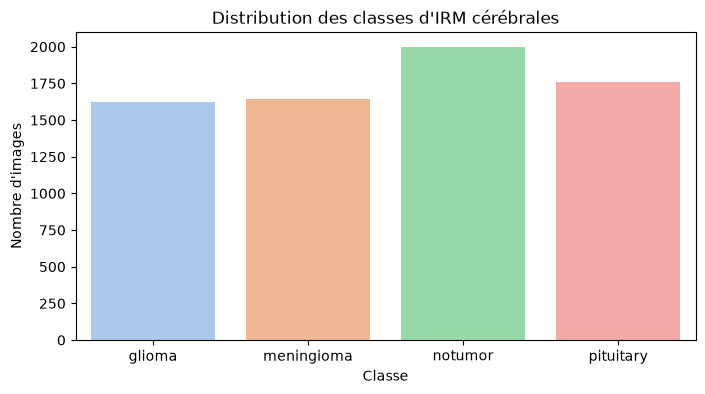

In [18]:

plt.figure(figsize=(8, 4))
sns.countplot(x=labels, order=class_names, palette="pastel")
plt.title("Distribution des classes d'IRM cérébrales")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.show()





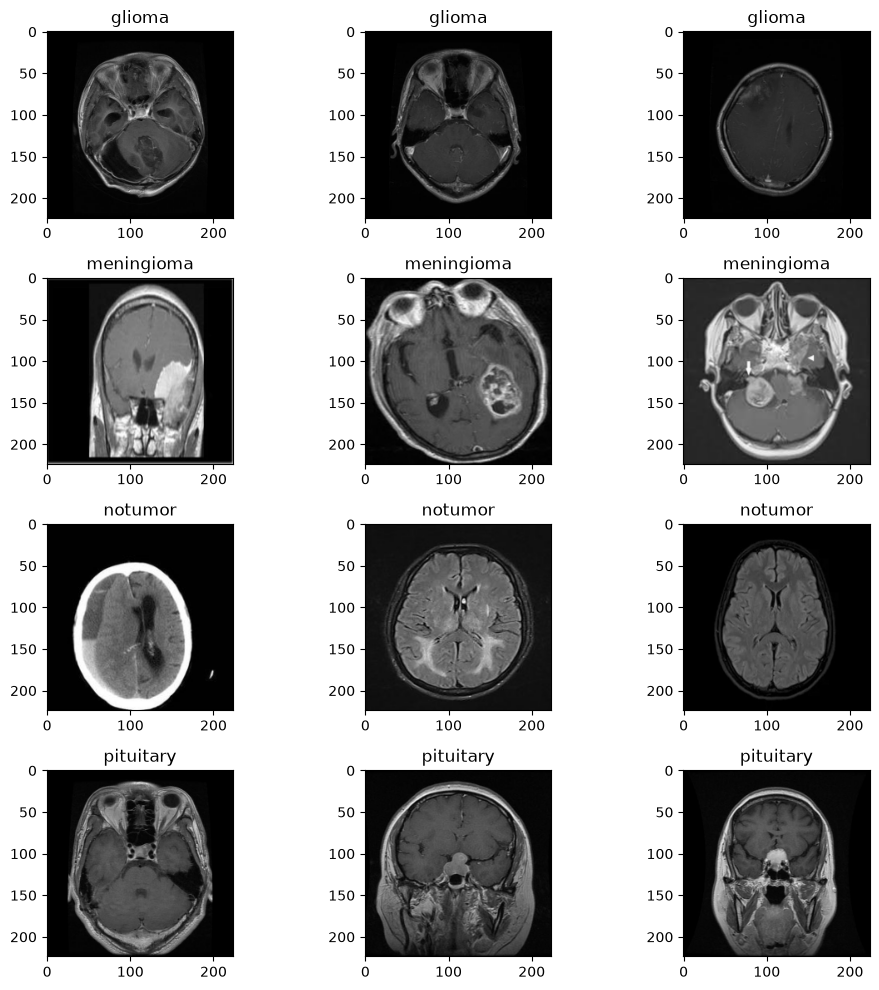

In [19]:
n=3
fig, axes = plt.subplots(len(class_names), n, figsize=(10, 10))
for i, cls in enumerate(class_names):
    sample_indices = [idx for idx, l in enumerate(labels) if l == cls][:n]
    for j, idx in enumerate(sample_indices):
        axes[i, j].imshow(X[idx])
        axes[i, j].set_title(cls)
        
plt.tight_layout()
plt.show()

In [20]:



le = LabelEncoder()
y_encoded = le.fit_transform(labels)
X_arr = np.array(X, dtype=np.uint8)


X_train, X_temp, y_train, y_temp = train_test_split(
    X_arr, y_encoded, test_size=0.30, random_state=42, stratify=y_encoded
)


X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Train : {len(X_train)} ({len(X_train)/len(X_arr):.0%})")
print(f"Val   : {len(X_val)} ({len(X_val)/len(X_arr):.0%})")
print(f"Test  : {len(X_test)} ({len(X_test)/len(X_arr):.0%})")


Train : 4916 (70%)
Val   : 1053 (15%)
Test  : 1054 (15%)


Balanced Train set class distribution:
  glioma: 1400 images
  meningioma: 1400 images
  notumor: 1400 images
  pituitary: 1400 images


C:\Users\anas\AppData\Local\Temp\ipykernel_14616\1855397207.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train, order=class_names, palette="pastel")


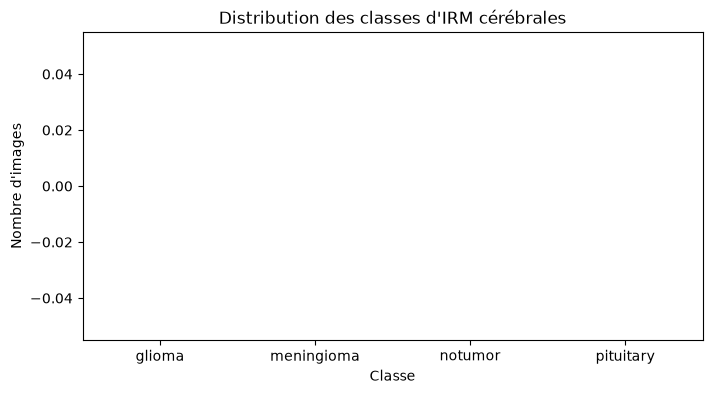

In [ ]:
# Balance classes so each class has the same count as the majority class
from collections import Counter
import random

def augment_image(image):
    aug_img = image.copy()
    
    flip_choice = random.choice([0, 1, -1, None])
    if flip_choice is not None:
        aug_img = cv2.flip(aug_img, flip_choice)
        
    if random.random() > 0.5:
        aug_img = cv2.GaussianBlur(aug_img, (5, 5), 0)
        
    if random.random() > 0.5:
        noise = np.random.normal(0, 12, aug_img.shape).astype(np.float32)
        aug_img = np.clip(aug_img.astype(np.float32) + noise, 0, 255).astype(np.uint8)
        
    return aug_img



counts = Counter(y_train)
max_count = max(counts.values())

balanced_X = list(X_train)
balanced_y = list(y_train)

for class_idx, count in counts.items():
    diff = max_count - count
    if diff > 0:
        # Pick images belonging to this class and augment only `diff` times
        cls_imgs = [img for img, l in zip(X_train, y_train) if l == class_idx]
        for i in range(diff):
            chosen_img = cls_imgs[i % len(cls_imgs)]
            balanced_X.append(augment_image(chosen_img))
            balanced_y.append(class_idx)

X_train_balanced = np.array(balanced_X, dtype=np.uint8)
y_train_balanced = np.array(balanced_y)

print("Balanced Train set class distribution:")
for idx, name in enumerate(class_names):
    print(f"  {name}: {np.sum(y_train_balanced == idx)} images")





In [28]:
# 1. Normalize pixel values (0 to 1)
X_train_norm = X_train_balanced / 255.0
X_val_norm = X_val / 255.0
X_test_norm = X_test / 255.0

# 2. Convert labels to one-hot encoding
from tensorflow.keras.utils import to_categorical

y_train_cat = to_categorical(y_train_balanced, num_classes=4)
y_val_cat = to_categorical(y_val, num_classes=4)
y_test_cat = to_categorical(y_test, num_classes=4)

print("X_train:", X_train_norm.shape, "y_train:", y_train_cat.shape)
print("X_val:  ", X_val_norm.shape, "y_val:  ", y_val_cat.shape)
print("X_test: ", X_test_norm.shape, "y_test: ", y_test_cat.shape)


X_train: (5600, 224, 224, 3) y_train: (5600, 4)
X_val:   (1053, 224, 224, 3) y_val:   (1053, 4)
X_test:  (1054, 224, 224, 3) y_test:  (1054, 4)


In [ ]:
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras import layers, models


base_model = InceptionV3(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

# add custom classification head
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(4, activation="softmax")
])


model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,065,572 (84.17 MB)

 Trainable params: 262,788 (1.00 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [32]:
# Train the model (Feature Extraction)
history = model.fit(
    X_train_norm, y_train_cat,
    validation_data=(X_val_norm, y_val_cat),
    epochs=10,
    batch_size=32
)


Epoch 1/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 300s 2s/step - accuracy: 0.7789 - loss: 0.5686 - val_accuracy: 0.8357 - val_loss: 0.4422
Epoch 2/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 347s 2s/step - accuracy: 0.8404 - loss: 0.4024 - val_accuracy: 0.8689 - val_loss: 0.3401
Epoch 3/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 314s 2s/step - accuracy: 0.8720 - loss: 0.3334 - val_accuracy: 0.8775 - val_loss: 0.3048
Epoch 4/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 313s 2s/step - accuracy: 0.8888 - loss: 0.2804 - val_accuracy: 0.8889 - val_loss: 0.3085
Epoch 5/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 305s 2s/step - accuracy: 0.8996 - loss: 0.2592 - val_accuracy: 0.9003 - val_loss: 0.2639
Epoch 6/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 295s 2s/step - accuracy: 0.9205 - loss: 0.2262 - val_accuracy: 0.8946 - val_loss: 0.2638
Epoch 7/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 296s 2s/step - accuracy: 0.9259 - loss: 0.2062 - val_accuracy: 0.9012 - val_loss: 0.2838
Epoch 8/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 332s 2s/step - accuracy: 0.9271 - loss: 0.1890 - val_accu

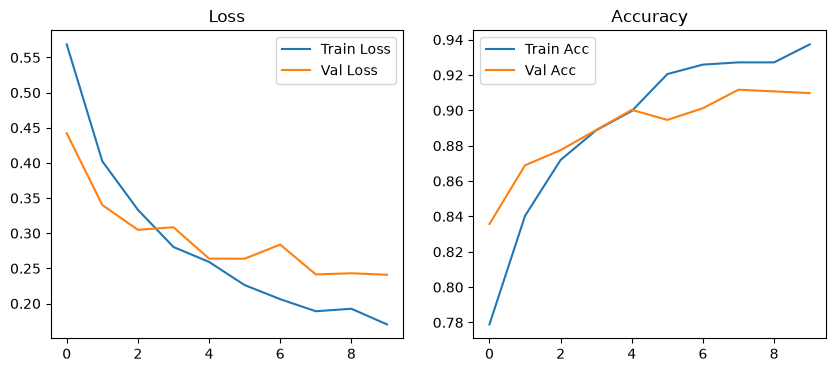

In [33]:
# Plot training curves
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.title("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train Acc")
plt.plot(history.history["val_accuracy"], label="Val Acc")
plt.title("Accuracy")
plt.legend()

plt.show()


33/33 ━━━━━━━━━━━━━━━━━━━━ 36s 977ms/step
Classification Report:
              precision    recall  f1-score   support

      glioma       0.94      0.89      0.91       243
  meningioma       0.86      0.78      0.82       247
     notumor       0.96      0.99      0.98       300
   pituitary       0.89      0.97      0.93       264

    accuracy                           0.91      1054
   macro avg       0.91      0.91      0.91      1054
weighted avg       0.91      0.91      0.91      1054



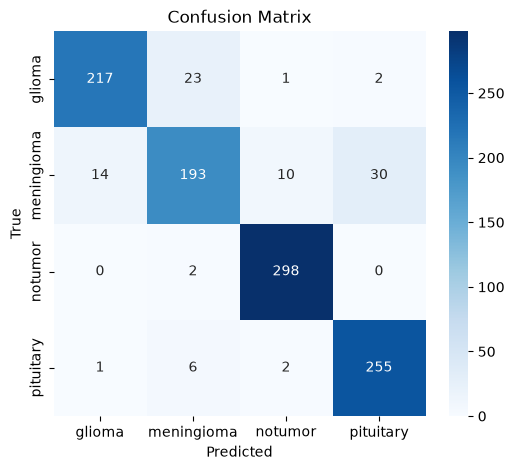

In [34]:
from sklearn.metrics import classification_report, confusion_matrix

# Predict on test set
y_pred = model.predict(X_test_norm)
y_pred_classes = np.argmax(y_pred, axis=1)

# Print metrics
print("Classification Report:")
print(classification_report(y_test, y_pred_classes, target_names=class_names))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


In [1]:
# Fine-Tuning: unfreeze base model and train with low learning rate
base_model.trainable = True

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_ft = model.fit(
    X_train_norm, y_train_cat,
    validation_data=(X_val_norm, y_val_cat),
    epochs=5,
    batch_size=32
)


NameError: name 'base_model' is not defined

In [ ]:
# Save the trained model
os.makedirs("../models", exist_ok=True)
model.save("../models/googlenet_brain_tumor.keras")
print("Model saved successfully to ../models/googlenet_brain_tumor.keras")


# Part 2: Brain Tumor Detection & Localization with YOLOv8


In [ ]:
# 1. Visualize a sample annotated image with its YOLO bounding box
import cv2
import matplotlib.pyplot as plt

sample_img = "../data/raw2/Train/Glioma/images/gg (1).jpg"
sample_lbl = "../data/raw2/Train/Glioma/labels/gg (1).txt"

img = cv2.imread(sample_img)
h, w, _ = img.shape

# Read and draw YOLO box (class_id, x_center, y_center, width, height)
with open(sample_lbl, "r") as f:
    for line in f:
        cls_id, xc, yc, bw, bh = map(float, line.strip().split())
        x1 = int((xc - bw / 2) * w)
        y1 = int((yc - bh / 2) * h)
        x2 = int((xc + bw / 2) * w)
        y2 = int((yc + bh / 2) * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(img, f"Class {int(cls_id)}", (x1, max(y1 - 5, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Sample Annotated MRI (YOLO format)")
plt.axis("off")
plt.show()


In [ ]:
import os
import shutil
import yaml

# 1. Create target YOLO folders
for split in ["train", "val"]:
    os.makedirs(f"../data/yolo/images/{split}", exist_ok=True)
    os.makedirs(f"../data/yolo/labels/{split}", exist_ok=True)

# 2. Copy images and labels into standard YOLO structure
source_splits = {"train": "Train", "val": "Val"}
classes = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

for target_split, raw_split in source_splits.items():
    for cls in classes:
        img_dir = f"../data/raw2/{raw_split}/{cls}/images"
        lbl_dir = f"../data/raw2/{raw_split}/{cls}/labels"
        
        for file in os.listdir(img_dir):
            base_name, _ = os.path.splitext(file)
            lbl_file = f"{base_name}.txt"
            
            # Match image with its label file
            if os.path.exists(os.path.join(lbl_dir, lbl_file)):
                shutil.copy(os.path.join(img_dir, file), f"../data/yolo/images/{target_split}/{file}")
                shutil.copy(os.path.join(lbl_dir, lbl_file), f"../data/yolo/labels/{target_split}/{lbl_file}")

print(f"YOLO Train images: {len(os.listdir('../data/yolo/images/train'))}")
print(f"YOLO Val images:   {len(os.listdir('../data/yolo/images/val'))}")

# 3. Create data.yaml
data_yaml = {
    "path": os.path.abspath("../data/yolo"),
    "train": "images/train",
    "val": "images/val",
    "nc": 4,
    "names": ["glioma", "meningioma", "no_tumor", "pituitary"]
}

with open("../data/data.yaml", "w") as f:
    yaml.dump(data_yaml, f, default_flow_style=False)

print("data.yaml successfully configured!")


In [ ]:
from ultralytics import YOLO

# Load lightweight pre-trained YOLOv8 nano model
yolo_model = YOLO("yolov8n.pt")

# Train YOLOv8 on brain tumor dataset
results = yolo_model.train(
    data="../data/data.yaml",
    epochs=10,
    imgsz=640,
    batch=16,
    plots=True
)


In [ ]:
# Evaluate detection performance on validation set
metrics = yolo_model.val()

print("mAP@0.5:     ", metrics.box.map50)
print("mAP@0.5:0.95:", metrics.box.map)


In [ ]:
# Run prediction on sample validation image
import glob

val_sample = glob.glob("../data/yolo/images/val/*.jpg")[0]
pred_results = yolo_model.predict(val_sample)

# Display prediction
res_plotted = pred_results[0].plot()
plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(res_plotted, cv2.COLOR_BGR2RGB))
plt.title("YOLOv8 Detection Prediction")
plt.axis("off")
plt.show()

# Save final best weights to models/
best_weights = yolo_model.trainer.best
shutil.copy(best_weights, "../models/yolov8_brain_tumor.pt")
print("Saved YOLOv8 model to ../models/yolov8_brain_tumor.pt")
